In [1]:
# ============================================================
# 1 · Imports
# ============================================================

import os
import glob
import warnings
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, clear_output
import ipywidgets as widgets

warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["image.cmap"] = "viridis"

In [2]:
# ============================================================
# 2 · Import extracted PPP sigma algorithms
# ============================================================
import importlib
import ppp_sigma_algorithms
importlib.reload(ppp_sigma_algorithms)

from ppp_sigma_algorithms import (
    EPS_LOG,
    prepare_grid,
    ppp_loglik_score,
    ppp_default_MMD,
    score_grid,
    score_sigma_zero,
    gaussianize_grid,
    optimize_sigma_for_grid_naive,
    optimize_sigma_for_grid,
    gaussian_kernel_and_first_derivative,
    gaussian_kernel_and_derivatives,
    eval_score_grad_sigma,
    eval_score_grad_hess_sigma,
    get_selected_interval_from_best_idx,
    quadratic_peak,
    refine_sigma_with_first_derivative,
    optimize_sigma_newton_robust_with_history,
    optimize_sigma_hybrid_group_then_grad,
    optimize_sigma_ternary_for_grid,
    optimize_sigma_golden_for_grid,
    optimize_sigma_dispatch,
)

print("Imported ppp_sigma_algorithms successfully.")

Imported ppp_sigma_algorithms successfully.


In [3]:
# ============================================================
# 3 · Configuration & Path Setup
# ============================================================

# Adjust these paths if needed
H5_DIRS = {
    "test_gen_data_meric_1500_13606074": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_1500_13606074/20260327_133317/metric_eval_data/test"
    ),
    "test_gen_data_meric_13600264": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test"
    ),
    "test_gen_data_meric_1500_13603608_LR_load_model40000": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_1500_13603608/20260327_012815/metric_eval_data/test"
    ),
}

ACTIVE_MODEL = "test_gen_data_meric_13600264"
H5_DIR = H5_DIRS[ACTIVE_MODEL]

assert os.path.isdir(H5_DIR), f"H5 directory not found: {H5_DIR}"

GT_DOT_SIZE = 16

h5_files = sorted(glob.glob(os.path.join(H5_DIR, "rank*.h5")))

print(f"Active model : {ACTIVE_MODEL}")
print(f"H5_DIR       : {H5_DIR}")
print(f"Found {len(h5_files)} h5 file(s)")
for p in h5_files:
    print(" ", p)

Active model : test_gen_data_meric_13600264
H5_DIR       : /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test
Found 4 h5 file(s)
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank00.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank01.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank02.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank03.h5


In [4]:
# ============================================================
# 4 · H5 Helpers
# ============================================================

def list_h5_samples(h5_paths):
    entries = []
    for path in h5_paths:
        with h5py.File(path, "r") as f:
            for key in sorted(f.keys()):
                entries.append((path, key))
    return entries


def load_h5_sample(h5_path, sample_key):
    with h5py.File(h5_path, "r") as f:
        grp = f[sample_key]
        img         = grp["img"][:]
        pred_lambda = grp["pred_lambda"][:].astype(np.float64)
        gt_support  = grp["gt_support"][:].astype(np.float64)

    H, W = pred_lambda.shape
    expected_count = float(pred_lambda.sum())
    gt_count = int((gt_support > 0).sum())

    return {
        "img": img,
        "pred_lambda": pred_lambda,
        "gt_support": gt_support,
        "ppp": {
            "H": H,
            "W": W,
            "img_area": H * W,
            "expected_count": expected_count,
            "gt_count": gt_count,
            "count_error": expected_count - gt_count,
        },
        "meta": {
            "h5_file": os.path.basename(h5_path),
            "sample_key": sample_key,
            "h5_path": h5_path,
        },
    }


all_samples = list_h5_samples(h5_files)

print(f"Total samples across all rank files: {len(all_samples)}")
print("First 5 entries:")
for entry in all_samples[:5]:
    print(" ", os.path.basename(entry[0]), "/", entry[1])

Total samples across all rank files: 500
First 5 entries:
  rank00.h5 / sample_000000
  rank00.h5 / sample_000001
  rank00.h5 / sample_000002
  rank00.h5 / sample_000003
  rank00.h5 / sample_000004


In [5]:
# ============================================================
# 5 · Visualization helper
# ============================================================

def show_sample_triptych(sample, title_prefix=""):
    img = sample["img"]
    pred_lambda = sample["pred_lambda"]
    gt_support = sample["gt_support"]
    ppp = sample["ppp"]
    meta = sample["meta"]

    ys, xs = np.where(gt_support > 0)

    fig, axes = plt.subplots(1, 3, figsize=(21, 5))

    axes[0].imshow(img, aspect="auto")
    axes[0].set_title(f"{title_prefix}Image\n{meta['sample_key']}")
    axes[0].axis("off")

    im = axes[1].imshow(pred_lambda, cmap="hot", aspect="auto")
    axes[1].set_title(rf"{title_prefix}Predicted $\lambda$" + f"\nE[N]={ppp['expected_count']:.2f}")
    axes[1].axis("off")
    plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

    axes[2].imshow(img, aspect="auto")
    axes[2].scatter(xs, ys, s=GT_DOT_SIZE, c="lime", linewidths=0, alpha=0.9)
    axes[2].set_title(f"{title_prefix}GT overlay\nN={ppp['gt_count']}")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

In [6]:
# ============================================================
# 6 · Sampling Helpers
# ============================================================

def sample_ppp_by_thinning(
    lambda_grid: np.ndarray,
    *,
    pixel_area: float | None = None,
    rng: np.random.Generator | None = None,
):
    if rng is None:
        rng = np.random.default_rng()

    lam = np.asarray(lambda_grid, dtype=np.float64)
    assert np.all(lam >= 0)
    H, W = lam.shape

    lambda_max = lam.max()
    if lambda_max == 0:
        return np.zeros((0, 2)), 0, 0.0, 0

    area_total = H * W
    Lambda_hom = lambda_max * area_total
    N_prop = rng.poisson(Lambda_hom)

    if N_prop == 0:
        return np.zeros((0, 2)), 0, lambda_max, 0

    xs = rng.random(N_prop) * W
    ys = rng.random(N_prop) * H
    xi = np.clip(xs.astype(int), 0, W - 1)
    yi = np.clip(ys.astype(int), 0, H - 1)

    lam_x = lam[yi, xi]
    accept_prob = lam_x / lambda_max
    keep = rng.random(N_prop) < accept_prob

    points_xy = np.stack([xs[keep], ys[keep]], axis=1)
    return points_xy, points_xy.shape[0], float(lambda_max), N_prop


def point_list_to_count_grid(points_xy, shape):
    H, W = shape
    grid = np.zeros((H, W), dtype=np.float64)

    if points_xy is None or len(points_xy) == 0:
        return grid

    points_xy = np.asarray(points_xy, dtype=np.float64)
    xs = np.floor(points_xy[:, 0]).astype(int)
    ys = np.floor(points_xy[:, 1]).astype(int)

    valid = (xs >= 0) & (xs < W) & (ys >= 0) & (ys < H)
    xs = xs[valid]
    ys = ys[valid]

    np.add.at(grid, (ys, xs), 1.0)
    return grid


def sample_point_cloud_from_lambda(
    pred_lambda,
    rng=None,
    mode="thinning",
    gt_count=None,
    block_size=8,
    placement="weighted",
    pixel_area=1.0,
):
    rng = np.random.default_rng() if rng is None else rng
    lam = np.asarray(pred_lambda, dtype=np.float64)

    if lam.ndim != 2:
        raise ValueError("pred_lambda must be 2D")
    if not np.all(np.isfinite(lam)):
        raise ValueError("pred_lambda contains NaN/Inf")
    if np.any(lam < 0):
        raise ValueError("pred_lambda contains negative values")

    H, W = lam.shape

    if mode == "thinning":
        points_xy, n_points, lambda_max, n_prop = sample_ppp_by_thinning(
            lam,
            pixel_area=pixel_area,
            rng=rng,
        )

        point_grid = point_list_to_count_grid(points_xy, (H, W))

        sampled_meta = {
            "mode": "thinning",
            "num_points": int(n_points),
            "grid_count_sum": int(point_grid.sum()),
            "binary_count": int((point_grid > 0).sum()),
            "lambda_max": float(lambda_max),
            "n_proposals": int(n_prop),
            "expected_count_input": float(lam.sum()),
        }
        return point_grid, sampled_meta

    raise ValueError("Currently only mode='thinning' is included in this test notebook.")

In [7]:
# ============================================================
# Helper: Extract sigma-score pairs from current algo outputs
# ============================================================

import numpy as np


def extract_eval_rows_from_result(res, *, h5_file, sample_key, input_type, algo):
    rows = []

    if res is None:
        return rows

    # --------------------------------------------------------
    # grid_naive / grid
    # --------------------------------------------------------
    if ("sigma_grid" in res) and ("scores" in res):
        sigma_arr = np.asarray(res["sigma_grid"], dtype=np.float64)
        score_arr = np.asarray(res["scores"], dtype=np.float64)

        n = min(len(sigma_arr), len(score_arr))
        for i in range(n):
            rows.append({
                "h5_file": h5_file,
                "sample_key": sample_key,
                "input_type": input_type,
                "algo": algo,
                "stage": "main",
                "eval_idx": int(i),
                "sigma": float(sigma_arr[i]),
                "score": float(score_arr[i]),
            })
        return rows

    # --------------------------------------------------------
    # newton / ternary / golden / direct history-based methods
    # --------------------------------------------------------
    if ("sigma_history" in res) and ("score_history" in res):
        sigma_arr = np.asarray(res["sigma_history"], dtype=np.float64)
        score_arr = np.asarray(res["score_history"], dtype=np.float64)

        n = min(len(sigma_arr), len(score_arr))
        for i in range(n):
            rows.append({
                "h5_file": h5_file,
                "sample_key": sample_key,
                "input_type": input_type,
                "algo": algo,
                "stage": "main",
                "eval_idx": int(i),
                "sigma": float(sigma_arr[i]),
                "score": float(score_arr[i]),
            })
        return rows

    # --------------------------------------------------------
    # hybrid: coarse + refinement
    # --------------------------------------------------------
    if "coarse" in res:
        coarse = res.get("coarse", None)
        if coarse is not None and ("sigma_grid" in coarse) and ("scores" in coarse):
            sigma_arr = np.asarray(coarse["sigma_grid"], dtype=np.float64)
            score_arr = np.asarray(coarse["scores"], dtype=np.float64)

            n = min(len(sigma_arr), len(score_arr))
            for i in range(n):
                rows.append({
                    "h5_file": h5_file,
                    "sample_key": sample_key,
                    "input_type": input_type,
                    "algo": algo,
                    "stage": "coarse",
                    "eval_idx": int(i),
                    "sigma": float(sigma_arr[i]),
                    "score": float(score_arr[i]),
                })

        refinement = res.get("refinement", None)
        if refinement is not None and ("sigma_history" in refinement) and ("score_history" in refinement):
            sigma_arr = np.asarray(refinement["sigma_history"], dtype=np.float64)
            score_arr = np.asarray(refinement["score_history"], dtype=np.float64)

            n = min(len(sigma_arr), len(score_arr))
            for i in range(n):
                rows.append({
                    "h5_file": h5_file,
                    "sample_key": sample_key,
                    "input_type": input_type,
                    "algo": algo,
                    "stage": "refinement",
                    "eval_idx": int(i),
                    "sigma": float(sigma_arr[i]),
                    "score": float(score_arr[i]),
                })

    return rows

In [8]:
# ============================================================
# 6 · Interactive sample selection tool
# ============================================================

selected_samples = []   # list of (h5_path, sample_key)

n = len(all_samples)

slider = widgets.IntSlider(
    value=0,
    min=0,
    max=max(0, n - 1),
    step=1,
    description="Sample:",
    continuous_update=False,
    layout=widgets.Layout(width="700px"),
)

btn_add = widgets.ToggleButton(
    value=False,
    description="☆ Add to selection",
    button_style="",
    layout=widgets.Layout(width="180px"),
)

btn_prev = widgets.Button(
    description="← Prev",
    layout=widgets.Layout(width="100px"),
)

btn_next = widgets.Button(
    description="Next →",
    layout=widgets.Layout(width="100px"),
)

btn_clear = widgets.Button(
    description="Clear selection",
    button_style="warning",
    layout=widgets.Layout(width="150px"),
)

btn_print = widgets.Button(
    description="Print selection",
    layout=widgets.Layout(width="130px"),
)

lbl_status = widgets.Label(value="0 selected")

plot_out = widgets.Output()
select_out = widgets.Output()


def _entry_of_idx(idx):
    h5_path, key = all_samples[idx]
    return (h5_path, key)


def _entry_label(entry):
    h5_path, key = entry
    return f"{os.path.basename(h5_path)} / {key}"


def _update_button_state(idx):
    entry = _entry_of_idx(idx)
    is_selected = entry in selected_samples
    btn_add.value = is_selected
    btn_add.description = "★ In selection" if is_selected else "☆ Add to selection"
    btn_add.button_style = "success" if is_selected else ""


def _refresh_status():
    lbl_status.value = f"{len(selected_samples)} selected"


def _render_selection_list():
    with select_out:
        clear_output(wait=True)
        print("Selected samples:")
        if not selected_samples:
            print("  (none)")
        else:
            for i, entry in enumerate(selected_samples):
                print(f"  {i:3d}: {_entry_label(entry)}")


def _render_current(idx):
    sample = load_h5_sample(*all_samples[idx])
    with plot_out:
        clear_output(wait=True)
        show_sample_triptych(sample, title_prefix=f"[{idx}] ")


def _full_refresh(idx):
    _update_button_state(idx)
    _refresh_status()
    _render_current(idx)
    _render_selection_list()


def _on_slider_change(change):
    if change["name"] == "value":
        _full_refresh(change["new"])


def _on_toggle_change(change):
    if change["name"] != "value":
        return

    idx = slider.value
    entry = _entry_of_idx(idx)

    if change["new"]:
        if entry not in selected_samples:
            selected_samples.append(entry)
    else:
        if entry in selected_samples:
            selected_samples.remove(entry)

    _full_refresh(idx)


def _on_prev_clicked(_):
    slider.value = max(slider.min, slider.value - 1)


def _on_next_clicked(_):
    slider.value = min(slider.max, slider.value + 1)


def _on_clear_clicked(_):
    selected_samples.clear()
    _full_refresh(slider.value)


def _on_print_clicked(_):
    _render_selection_list()


slider.observe(_on_slider_change, names="value")
btn_add.observe(_on_toggle_change, names="value")
btn_prev.on_click(_on_prev_clicked)
btn_next.on_click(_on_next_clicked)
btn_clear.on_click(_on_clear_clicked)
btn_print.on_click(_on_print_clicked)

controls = widgets.HBox([btn_prev, btn_next, btn_add, btn_clear, btn_print])
ui = widgets.VBox([slider, controls, lbl_status, plot_out, select_out])

display(ui)
_full_refresh(0)

In [20]:
# ============================================================
# 7 · Optional: inspect current selected samples as plain list
# ============================================================

print(f"{len(selected_samples)} selected samples")
for i, entry in enumerate(selected_samples):
    print(f"{i:3d}: {os.path.basename(entry[0])} / {entry[1]}")

3 selected samples
  0: rank00.h5 / sample_000000
  1: rank01.h5 / sample_000006
  2: rank01.h5 / sample_000086


In [21]:
# ============================================================
# 8 · Define all algorithms to be run
#    with all currently available parameters made explicit
# ============================================================

POINT_SAMPLING_MODE = "thinning"   # "thinning" or "block_bernoulli"
SIGMA_GRID = np.linspace(0.0, 120.0, 40)

ALGORITHM_SPECS = {
    "Naive grid search": dict(
        method="grid_naive",
        sigma_grid=SIGMA_GRID,
        verbose=False,
        eps_h=EPS_LOG,
    ),

    "Efficient grid search": dict(
        method="grid",
        sigma_grid=SIGMA_GRID,
        verbose=False,
        truncate=4.0,
        eps_h=EPS_LOG,
    ),

    "Newton method": dict(
        method="newton",
        initial_checks=(0.0, 1.0, 50.0, 100.0, 120.0),
        verbose=False,
        sigma_min=0.0,
        sigma_max=120.0,
        max_iter=20,
        tol_g=1e-6,
        tol_sigma=1e-2,
        min_step=2.0,
        max_step=20.0,
        eps_h=EPS_LOG,
    ),

    # "hybrid": dict(
    #     method="hybrid",
    #     sigma_max=120.0,
    #     n_coarse=5,
    #     loss_tol=1e-3,
    #     truncate=4.0,
    #     refine_max_iter=50,
    #     verbose=False,
    # ),

    # "ternary": dict(
    #     method="ternary",
    #     sigma_min=0.0,
    #     sigma_max=120.0,
    #     max_iter=30,
    #     tol_sigma=0.01,
    #     eps_h=EPS_LOG,
    #     check_zero=True,
    #     verbose=False,
    # ),

    "Golden-section search": dict(
        method="golden",
        sigma_min=0.0,
        sigma_max=120.0,
        max_iter=30,
        tol_sigma=0.5,
        eps_h=EPS_LOG,
        check_zero=True,
        verbose=False,
    ),
}

print("Algorithms:")
for k, v in ALGORITHM_SPECS.items():
    print(f"  {k}:")
    for kk, vv in v.items():
        print(f"    {kk} = {vv}")

Algorithms:
  Naive grid search:
    method = grid_naive
    sigma_grid = [  0.           3.07692308   6.15384615   9.23076923  12.30769231
  15.38461538  18.46153846  21.53846154  24.61538462  27.69230769
  30.76923077  33.84615385  36.92307692  40.          43.07692308
  46.15384615  49.23076923  52.30769231  55.38461538  58.46153846
  61.53846154  64.61538462  67.69230769  70.76923077  73.84615385
  76.92307692  80.          83.07692308  86.15384615  89.23076923
  92.30769231  95.38461538  98.46153846 101.53846154 104.61538462
 107.69230769 110.76923077 113.84615385 116.92307692 120.        ]
    verbose = False
    eps_h = 1e-12
  Efficient grid search:
    method = grid
    sigma_grid = [  0.           3.07692308   6.15384615   9.23076923  12.30769231
  15.38461538  18.46153846  21.53846154  24.61538462  27.69230769
  30.76923077  33.84615385  36.92307692  40.          43.07692308
  46.15384615  49.23076923  52.30769231  55.38461538  58.46153846
  61.53846154  64.61538462  67.6923

In [28]:
# ============================================================
# 9 · Run all algorithms on all selected samples
#     for both:
#     - heatmap
#     - sampled point cloud
# ============================================================

import time
import numpy as np
import pandas as pd

if len(selected_samples) == 0:
    raise ValueError("No samples selected. Use the interactive tool first.")

results = []
eval_rows = []

for sample_idx, (h5_path, sample_key) in enumerate(selected_samples):
    print("=" * 110)
    print(f"[{sample_idx + 1}/{len(selected_samples)}] {os.path.basename(h5_path)} / {sample_key}")

    sample = load_h5_sample(h5_path, sample_key)
    pred_lambda = sample["pred_lambda"]
    gt_support = sample["gt_support"]
    ppp = sample["ppp"]
    meta = sample["meta"]

    sampled_pc_grid, sampled_pc_meta = sample_point_cloud_from_lambda(
        pred_lambda,
        rng=np.random.default_rng(sample_idx),
        mode="thinning",
        gt_count=ppp["gt_count"],
    )

    inputs_to_test = {
        "heatmap": {
            "grid": pred_lambda,
            "input_meta": {},
        },
        "sampled_pointcloud": {
            "grid": sampled_pc_grid,
            "input_meta": sampled_pc_meta,
        },
    }

    for input_type, input_payload in inputs_to_test.items():
        grid = input_payload["grid"]
        input_meta = input_payload["input_meta"]

        print(f"  INPUT: {input_type}")

        for algo_name, algo_kwargs in ALGORITHM_SPECS.items():
            run_kwargs = dict(algo_kwargs)

            # verbose output der Algos anschalten
            run_kwargs["verbose"] = False

            print(f"    -> {algo_name}")

            try:
                t0 = time.perf_counter()

                res = optimize_sigma_dispatch(
                    grid,
                    gt_support,
                    score_kind="loglik", # mmd
                    **run_kwargs,
                )

                runtime_sec = time.perf_counter() - t0

                best_sigma = float(res.get("best_sigma", np.nan))
                best_score = float(res.get("best_score", np.nan))
                status = str(res.get("status", "ok"))

                print(
                    f"       DONE | "
                    f"time={runtime_sec:8.4f}s | "
                    f"opt_sigma={best_sigma:10.6f} | "
                    f"opt_score={best_score:12.6f} | "
                    f"status={status}"
                )

                results.append({
                    "h5_file": meta["h5_file"],
                    "sample_key": meta["sample_key"],
                    "input_type": input_type,
                    "expected_count": float(ppp["expected_count"]),
                    "gt_count": int(ppp["gt_count"]),
                    "algo": algo_name,
                    "best_sigma": best_sigma,
                    "best_score": best_score,
                    "status": status,
                    "runtime_sec": float(runtime_sec),
                    "sampled_num_points": (
                        int(input_meta.get("num_points")) if input_type == "sampled_pointcloud" else np.nan
                    ),
                    "sampled_grid_count_sum": (
                        int(input_meta.get("grid_count_sum")) if input_type == "sampled_pointcloud" else np.nan
                    ),
                    "sampled_binary_count": (
                        int(input_meta.get("binary_count")) if input_type == "sampled_pointcloud" else np.nan
                    ),
                    "result_obj": res,
                })

                # ----------------------------------------------------
                # sigma/score pairs aus dem bestehenden Resultat ziehen
                # ----------------------------------------------------
                eval_rows.extend(
                    extract_eval_rows_from_result(
                        res,
                        h5_file=meta["h5_file"],
                        sample_key=meta["sample_key"],
                        input_type=input_type,
                        algo=algo_name,
                    )
                )

            except Exception as e:
                err_msg = f"ERROR: {type(e).__name__}: {e}"
                print(f"       {err_msg}")

                results.append({
                    "h5_file": meta["h5_file"],
                    "sample_key": meta["sample_key"],
                    "input_type": input_type,
                    "expected_count": float(ppp["expected_count"]),
                    "gt_count": int(ppp["gt_count"]),
                    "algo": algo_name,
                    "best_sigma": np.nan,
                    "best_score": np.nan,
                    "status": err_msg,
                    "runtime_sec": np.nan,
                    "sampled_num_points": (
                        int(input_meta.get("num_points")) if input_type == "sampled_pointcloud" else np.nan
                    ),
                    "sampled_grid_count_sum": (
                        int(input_meta.get("grid_count_sum")) if input_type == "sampled_pointcloud" else np.nan
                    ),
                    "sampled_binary_count": (
                        int(input_meta.get("binary_count")) if input_type == "sampled_pointcloud" else np.nan
                    ),
                    "result_obj": None,
                })

df_results = pd.DataFrame(results)
df_eval = pd.DataFrame(eval_rows)

print("\nDone.")
print(f"Rows in df_results: {len(df_results)}")
print(f"Rows in df_eval   : {len(df_eval)}")

[1/12] rank00.h5 / sample_000000
  INPUT: heatmap
    -> Naive grid search
       DONE | time= 14.5237s | opt_sigma=  0.000000 | opt_score=    4.658996 | status=ok
    -> Efficient grid search
       DONE | time=  3.7701s | opt_sigma=  0.000000 | opt_score=    4.658996 | status=ok
    -> Newton method
       DONE | time= 20.4578s | opt_sigma=  0.000000 | opt_score=    4.658996 | status=sigma_tol_stop
    -> Golden-section search
       DONE | time=  0.1185s | opt_sigma=  0.000000 | opt_score=    4.658996 | status=ok
  INPUT: sampled_pointcloud
    -> Naive grid search
       DONE | time= 14.2879s | opt_sigma= 40.000000 | opt_score=    4.291942 | status=ok
    -> Efficient grid search
       DONE | time=  3.6654s | opt_sigma= 43.076923 | opt_score=    4.304258 | status=ok
    -> Newton method
       DONE | time= 16.3076s | opt_sigma= 41.079148 | opt_score=    4.310729 | status=sigma_tol_stop
    -> Golden-section search
       DONE | time=  3.6530s | opt_sigma= 40.814006 | opt_score=   

In [16]:
df_results[df_results['input_type'] == 'sampled_pointcloud']

,h5_file,sample_key,input_type,expected_count,gt_count,algo,best_sigma,best_score,status,runtime_sec,sampled_num_points,sampled_grid_count_sum,sampled_binary_count,result_obj
4,rank00.h5,sample_000000,sampled_pointcloud,106.851817,67,grid_group,43.076923,4.304258,ok,5.678212,111.0,111.0,111.0,"{'sigma_grid': [0.0, 3.076923076923077, 6.1538..."
5,rank00.h5,sample_000000,sampled_pointcloud,106.851817,67,hybrid,40.354398,4.292173,refined_with_first_derivative,5.461907,111.0,111.0,111.0,"{'best_sigma': 40.35439762044895, 'best_score'..."
6,rank00.h5,sample_000000,sampled_pointcloud,106.851817,67,ternary,40.873224,4.292315,ok,12.346400,111.0,111.0,111.0,"{'best_sigma': 40.87322419846817, 'best_score'..."
7,rank00.h5,sample_000000,sampled_pointcloud,106.851817,67,golden,40.814006,4.292310,ok,5.942847,111.0,111.0,111.0,"{'best_sigma': 40.81400589503589, 'best_score'..."
12,rank00.h5,sample_000001,sampled_pointcloud,190.103019,216,grid_group,30.769231,5.889925,ok,6.276513,171.0,171.0,170.0,"{'sigma_grid': [0.0, 3.076923076923077, 6.1538..."
13,rank00.h5,sample_000001,sampled_pointcloud,190.103019,216,hybrid,30.000000,5.842407,coarse_better_than_refinement,4.182323,171.0,171.0,170.0,"{'best_sigma': 30.0, 'best_score': 5.842407234..."
14,rank00.h5,sample_000001,sampled_pointcloud,190.103019,216,ternary,30.646663,5.885780,ok,8.749710,171.0,171.0,170.0,"{'best_sigma': 30.64666281480732, 'best_score'..."
15,rank00.h5,sample_000001,sampled_pointcloud,190.103019,216,golden,30.642809,5.885782,ok,4.300605,171.0,171.0,170.0,"{'best_sigma': 30.642808941532675, 'best_score..."
20,rank00.h5,sample_000002,sampled_pointcloud,156.930782,220,grid_group,12.307692,7.000938,ok,6.326184,163.0,163.0,163.0,"{'sigma_grid': [0.0, 3.076923076923077, 6.1538..."
21,rank00.h5,sample_000002,sampled_pointcloud,156.930782,220,hybrid,22.148299,6.837366,refined_with_first_derivative,3.214865,163.0,163.0,163.0,"{'best_sigma': 22.14829945295202, 'best_score'..."


# Computing the optimal values at the optimizer seperatly to determine accuracy of algorithm

Note: Code requires for the file and type to be set.

Note: The efficiently calculated grid search is not exact, because the gaussian noise added incrementally using the group property of the filter, does not add up to the exact value. This is because the filter on the pixel grid is discrete and not continuous (right? Boarder leakage?).

In [20]:
selected_h5 = [h5_path for h5_path, key in selected_samples if os.path.basename(h5_path) == h5_file_sel and key == sample_key_sel]
print(f"found {len(selected_h5)} matching h5 files for selection criteria")

found 0 matching h5 files for selection criteria


In [21]:
selected_samples

[('/mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank00.h5',
  'sample_000000'),
 ('/mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank00.h5',
  'sample_000001'),
 ('/mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank00.h5',
  'sample_000002')]

In [24]:
# ============================================================
# Re-evaluate all best_sigmas with the same canonical scorer
# raw, no caching, using scipy Gaussian blur
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# choose one sample / input_type to inspect
# ------------------------------------------------------------
h5_file_sel = "rank00.h5"
sample_key_sel = "sample_000000"
input_type_sel = "sampled_pointcloud"   # or "heatmap"

# ------------------------------------------------------------
# load the corresponding grid again
# ------------------------------------------------------------
selected_h5 = [h5_path for h5_path, key in selected_samples if os.path.basename(h5_path) == h5_file_sel and key == sample_key_sel]
print(f"found {len(selected_h5)} matching h5 files for selection criteria. Set h5_file_sel and sample_key_sel above.")
sample = load_h5_sample(
    selected_h5[0],
    sample_key_sel,
)

pred_lambda = sample["pred_lambda"]
gt_support = sample["gt_support"]
ppp = sample["ppp"]

if input_type_sel == "heatmap":
    grid_eval = pred_lambda
elif input_type_sel == "sampled_pointcloud":
    sampled_pc_grid, sampled_pc_meta = sample_point_cloud_from_lambda(
        pred_lambda,
        rng=np.random.default_rng(0),
        mode=POINT_SAMPLING_MODE,
        gt_count=ppp["gt_count"],
    )
    grid_eval = sampled_pc_grid
else:
    raise ValueError(f"Unknown input_type_sel: {input_type_sel}")

# ------------------------------------------------------------
# take the sigmas found by the algorithms
# ------------------------------------------------------------
df_sel = df_results[
    (df_results["h5_file"] == h5_file_sel) &
    (df_results["sample_key"] == sample_key_sel) &
    (df_results["input_type"] == input_type_sel)
].copy()

if len(df_sel) == 0:
    raise ValueError("No matching rows found in df_results.")

# ------------------------------------------------------------
# canonical raw re-evaluation
# ------------------------------------------------------------
rows = []

for _, row in df_sel.iterrows():
    algo = row["algo"]
    sigma = float(row["best_sigma"])

    h = gaussianize_grid(grid_eval, sigma)
    score_raw_scipy = ppp_loglik_score(
        h,
        gt_support,
        eps=EPS_LOG,
        normalize_by_gt=True,
    )

    rows.append({
        "algo": algo,
        "sigma_from_algo": sigma,
        "best_score_reported_by_algo": float(row["best_score"]),
        "score_recomputed_raw_scipy": float(score_raw_scipy),
        "score_difference": float(score_raw_scipy - row["best_score"]),
    })

df_recheck = pd.DataFrame(rows).sort_values("score_recomputed_raw_scipy", ascending=False).reset_index(drop=True)

print(f"h5_file    : {h5_file_sel}")
print(f"sample_key : {sample_key_sel}")
print(f"input_type : {input_type_sel}")
display(df_recheck.sort_values(by="score_recomputed_raw_scipy", ascending=False))

found 1 matching h5 files for selection criteria. Set h5_file_sel and sample_key_sel above.
h5_file    : rank00.h5
sample_key : sample_000000
input_type : sampled_pointcloud


,algo,sigma_from_algo,best_score_reported_by_algo,score_recomputed_raw_scipy,score_difference
0,ternary,40.873224,4.292315,4.292315,0.000000
1,golden,40.814006,4.292310,4.292310,0.000000
2,hybrid,40.354398,4.292173,4.292173,0.000000
3,grid_group,43.076923,4.304258,4.290655,-0.013603


In [47]:
# ============================================================
# 10 · Compact result table
# ============================================================

cols = [
    "h5_file",
    "sample_key",
    "expected_count",
    "gt_count",
    "algo",
    "best_sigma",
    "best_score",
    "status",
]

display(df_results[cols].sort_values(["sample_key", "algo"]).reset_index(drop=True))

,h5_file,sample_key,expected_count,gt_count,algo,best_sigma,best_score,status
0,rank00.h5,sample_000000,106.851817,67,golden,40.814006,4.292310,ok
1,rank00.h5,sample_000000,106.851817,67,grid_group,43.076923,4.304258,ok
2,rank00.h5,sample_000000,106.851817,67,hybrid,40.354398,4.292173,refined_with_first_derivative
3,rank00.h5,sample_000000,106.851817,67,ternary,40.873224,4.292315,ok
4,rank00.h5,sample_000002,156.930782,220,golden,25.952350,6.457814,ok
5,rank00.h5,sample_000002,156.930782,220,grid_group,24.615385,6.466161,ok
6,rank00.h5,sample_000002,156.930782,220,hybrid,27.808572,6.442591,refined_with_first_derivative
7,rank00.h5,sample_000002,156.930782,220,ternary,25.907052,6.458127,ok
8,rank00.h5,sample_000003,172.858436,191,golden,35.393026,5.628697,ok
9,rank00.h5,sample_000003,172.858436,191,grid_group,33.846154,5.633309,ok


# Plot MMD output for vis inspection

In [25]:
import numpy as np
import matplotlib.pyplot as plt


def sample_pointcloud_from_mass_grid(h, rng=None):
    """
    Sample a point cloud from a discrete PPP with per-pixel mass h.
    Returns:
        support : binary support grid
        counts  : sampled Poisson counts per pixel
    """
    h = np.asarray(h, dtype=np.float64)
    h = np.clip(h, 0.0, None)

    if rng is None:
        rng = np.random.default_rng()

    counts = rng.poisson(h)
    support = (counts > 0).astype(np.float64)
    return support, counts


def _validate_score_kind(score_kind):
    score_kind = str(score_kind).lower()
    if score_kind not in {"loglik", "mmd"}:
        raise ValueError(f"Unknown score_kind: {score_kind}")
    return score_kind


def _validate_output_mode(output_mode):
    output_mode = str(output_mode).lower()
    if output_mode not in {"sample", "heatmap"}:
        raise ValueError(f"Unknown output_mode: {output_mode}")
    return output_mode


def _extract_points_from_support(support):
    support = np.asarray(support)
    y, x = np.where(support > 0)
    return x.astype(np.float64), y.astype(np.float64)


def build_continuous_overlay_rgb(gt_smooth, gen_smooth, eps=1e-12):
    """
    Build a continuous RGB overlay with:
    - white: no signal in either map
    - green: overlap
    - red: mismatch / only one active
    """
    gt_smooth = np.asarray(gt_smooth, dtype=np.float64)
    gen_smooth = np.asarray(gen_smooth, dtype=np.float64)

    overlap_map = np.minimum(gt_smooth, gen_smooth)
    mismatch_map = np.abs(gt_smooth - gen_smooth)
    total_map = np.maximum(gt_smooth, gen_smooth)

    scale = float(total_map.max())
    if scale <= eps:
        rgb = np.ones(gt_smooth.shape + (3,), dtype=np.float64)
        return rgb, overlap_map, mismatch_map

    overlap_n = overlap_map / scale
    mismatch_n = mismatch_map / scale

    rgb = np.ones(gt_smooth.shape + (3,), dtype=np.float64)

    # green for overlap
    rgb[..., 0] = 1.0 - overlap_n
    # red for mismatch
    rgb[..., 1] = 1.0 - mismatch_n
    # white background where no signal
    rgb[..., 2] = 1.0 - np.clip(overlap_n + mismatch_n, 0.0, 1.0)

    rgb = np.clip(rgb, 0.0, 1.0)
    return rgb, overlap_map, mismatch_map


def plot_sigma_objective_curve(
    grid,
    gt_support,
    sigma_values,
    score_kind="loglik",
    eps_h=EPS_LOG,
    ax=None,
):
    """
    Plot score(sigma) for the given optimization input grid.
    """
    score_kind = _validate_score_kind(score_kind)
    sigma_values = np.asarray(sigma_values, dtype=np.float64)
    scores = []

    x = prepare_grid(grid)

    for sigma in sigma_values:
        sigma = float(sigma)

        if sigma == 0.0:
            score = score_sigma_zero(
                x,
                gt_support,
                eps_h=eps_h,
                normalize_by_gt=True,
                score_kind=score_kind,
            )
        else:
            h = gaussianize_grid(x, sigma)
            score = score_grid(
                h,
                gt_support,
                score_kind=score_kind,
                eps_h=eps_h,
                normalize_by_gt=True,
            )

        scores.append(float(score))

    scores = np.asarray(scores, dtype=np.float64)

    if ax is None:
        _, ax = plt.subplots(figsize=(8, 4))

    ax.plot(sigma_values, scores, linewidth=2)
    ax.set_xlabel("sigma")
    ax.set_ylabel(f"score ({score_kind})")
    ax.set_title(f"Optimization objective for input grid ({score_kind})")
    ax.grid(True, alpha=0.35)

    return scores


def plot_gt_input_and_optimal_blur(
    grid,
    gt_support,
    method="hybrid",
    score_kind="loglik",
    output_mode="sample",
    run_kwargs=None,
    rng_seed=0,
    sigma_curve_max=None,
    sigma_curve_num=120,
    figsize=(10, 30),
    point_size_raw=5,
):
    """
    Create 6 vertically stacked plots.

    output_mode="sample":
        1. GT raw point cloud
        2. Generated raw sampled point cloud from h_opt
        3. GT Gaussianized with sigma*
        4. Generated sample Gaussianized with sigma*
        5. Continuous overlay
        6. Loss curve

    output_mode="heatmap":
        1. GT raw point cloud
        2. Input heatmap (the optimization input grid)
        3. GT Gaussianized with sigma*
        4. Input heatmap Gaussianized with sigma*
        5. Continuous overlay
        6. Loss curve
    """
    if run_kwargs is None:
        run_kwargs = {}

    score_kind = _validate_score_kind(score_kind)
    output_mode = _validate_output_mode(output_mode)

    x = prepare_grid(grid)
    gt_support = (np.asarray(gt_support) > 0).astype(np.float64)

    if x.shape != gt_support.shape:
        raise ValueError("grid and gt_support must have the same shape")

    res = optimize_sigma_dispatch(
        x,
        gt_support,
        method=method,
        score_kind=score_kind,
        **run_kwargs,
    )

    sigma_opt = float(res["best_sigma"])
    score_opt = float(res["best_score"])

    # Optimized Gaussianized version of the input grid
    if sigma_opt == 0.0:
        h_opt = x.copy()
    else:
        h_opt = gaussianize_grid(x, sigma_opt)

    rng = np.random.default_rng(rng_seed)
    gt_x, gt_y = _extract_points_from_support(gt_support)

    sampled_support = None
    sampled_counts = None

    # GT smooth field for comparison
    if sigma_opt == 0.0:
        gt_smooth = gt_support.copy()
    else:
        gt_smooth = gaussianize_grid(gt_support, sigma_opt)

    if output_mode == "sample":
        sampled_support, sampled_counts = sample_pointcloud_from_mass_grid(h_opt, rng=rng)
        gen_x, gen_y = _extract_points_from_support(sampled_support)

        if sigma_opt == 0.0:
            gen_smooth = sampled_support.copy()
        else:
            gen_smooth = gaussianize_grid(sampled_support, sigma_opt)

        panel2_kind = "sample"
        panel2_data = sampled_support

    elif output_mode == "heatmap":
        gen_x, gen_y = None, None

        # Show the input heatmap raw, and its Gaussianized version separately
        panel2_kind = "heatmap"
        panel2_data = x
        gen_smooth = h_opt

    else:
        raise RuntimeError("Unreachable")

    overlay_rgb, overlap_map, mismatch_map = build_continuous_overlay_rgb(
        gt_smooth,
        gen_smooth,
    )

    H, W = x.shape

    if sigma_curve_max is None:
        sigma_curve_max = max(10.0, 1.25 * sigma_opt if sigma_opt > 0 else 10.0)

    sigma_values = np.linspace(0.0, sigma_curve_max, sigma_curve_num)

    fig, axes = plt.subplots(6, 1, figsize=figsize)

    # 1) GT raw point cloud
    ax = axes[0]
    ax.scatter(gt_x, gt_y, s=point_size_raw)
    ax.set_xlim(-0.5, W - 0.5)
    ax.set_ylim(H - 0.5, -0.5)
    ax.set_aspect("equal")
    ax.set_title(f"GT raw point cloud | count={len(gt_x)}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.grid(True, alpha=0.2)

    # 2) Generated output / heatmap input
    ax = axes[1]
    if panel2_kind == "sample":
        ax.scatter(gen_x, gen_y, s=point_size_raw)
        ax.set_xlim(-0.5, W - 0.5)
        ax.set_ylim(H - 0.5, -0.5)
        ax.set_aspect("equal")
        ax.set_title(
            f"Generated raw sampled point cloud | sampled_count={int(sampled_counts.sum())} | "
            f"sum(h_opt)={h_opt.sum():.4f}"
        )
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.grid(True, alpha=0.2)
    else:
        im = ax.imshow(panel2_data, interpolation="nearest")
        ax.set_title(f"Input heatmap (raw optimization input) | sum(grid)={x.sum():.4f}")
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02)

    # 3) GT Gaussianized with sigma*
    ax = axes[2]
    im = ax.imshow(gt_smooth, interpolation="nearest")
    ax.set_title(f"GT Gaussianized with sigma* = {sigma_opt:.6f}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02)

    # 4) Generated smooth / heatmap Gaussianized
    ax = axes[3]
    im = ax.imshow(gen_smooth, interpolation="nearest")
    if output_mode == "sample":
        ax.set_title(f"Generated sample Gaussianized with sigma* = {sigma_opt:.6f}")
    else:
        ax.set_title(f"Input heatmap Gaussianized with sigma* = {sigma_opt:.6f}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02)

    # 5) Continuous overlay
    ax = axes[4]
    ax.imshow(overlay_rgb, interpolation="nearest")
    ax.set_title("Continuous overlay | white=no signal, green=overlap, red=mismatch")
    ax.set_xlabel("x")
    ax.set_ylabel("y")

    # 6) Loss curve
    ax = axes[5]
    scores = plot_sigma_objective_curve(
        x,
        gt_support,
        sigma_values=sigma_values,
        score_kind=score_kind,
        ax=ax,
    )
    ax.axvline(sigma_opt, linestyle="--", alpha=0.8, label=f"sigma*={sigma_opt:.4f}")
    ax.scatter([sigma_opt], [score_opt], s=35, zorder=3, label=f"score*={score_opt:.6f}")
    ax.legend()
    ax.set_title(
        f"Loss curve | method={method}, score_kind={score_kind}, "
        f"output_mode={output_mode}, status={res.get('status', 'n/a')}"
    )

    plt.tight_layout()
    plt.show()

    return {
        "result": res,
        "h_opt": h_opt,
        "sampled_support": sampled_support,
        "sampled_counts": sampled_counts,
        "gt_smooth": gt_smooth,
        "gen_smooth": gen_smooth,
        "overlay_rgb": overlay_rgb,
        "overlap_map": overlap_map,
        "mismatch_map": mismatch_map,
        "sigma_values": sigma_values,
        "scores": scores,
        "output_mode": output_mode,
    }

In [28]:
selected_samples

[('/mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank00.h5',
  'sample_000000'),
 ('/mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank00.h5',
  'sample_000001'),
 ('/mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank00.h5',
  'sample_000002')]

In [29]:
h5_path, sample_key = selected_samples[0]

sample = load_h5_sample(h5_path, sample_key)
pred_lambda = sample["pred_lambda"]
gt_support = sample["gt_support"]
ppp = sample["ppp"]
meta = sample["meta"]

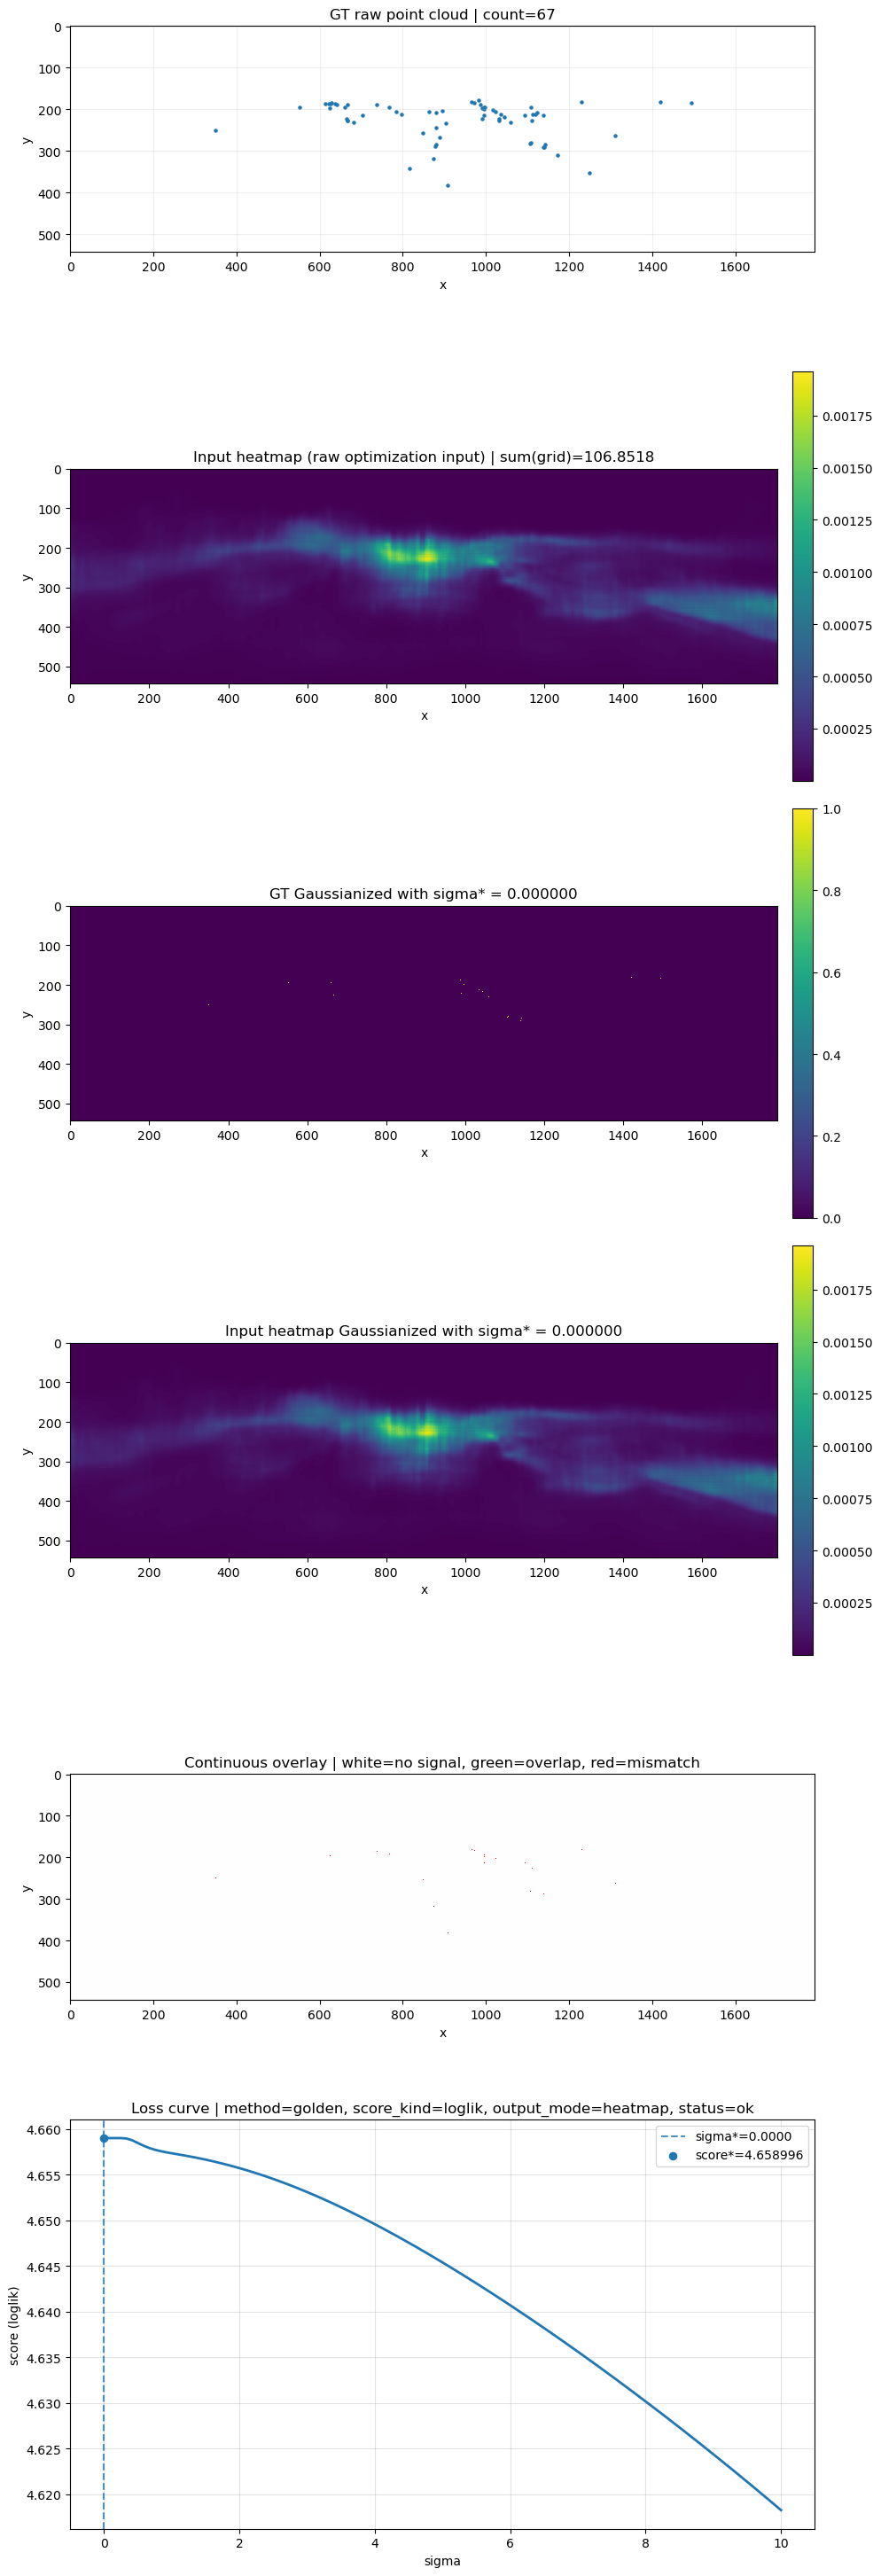

In [30]:
out = plot_gt_input_and_optimal_blur(
    grid=pred_lambda,
    gt_support=gt_support,
    method="golden",
    score_kind="loglik",
    output_mode="heatmap",
    run_kwargs=dict(
        sigma_min=0.0,
        sigma_max=120.0,
        max_iter=30,
        tol_sigma=0.5,
    ),
)

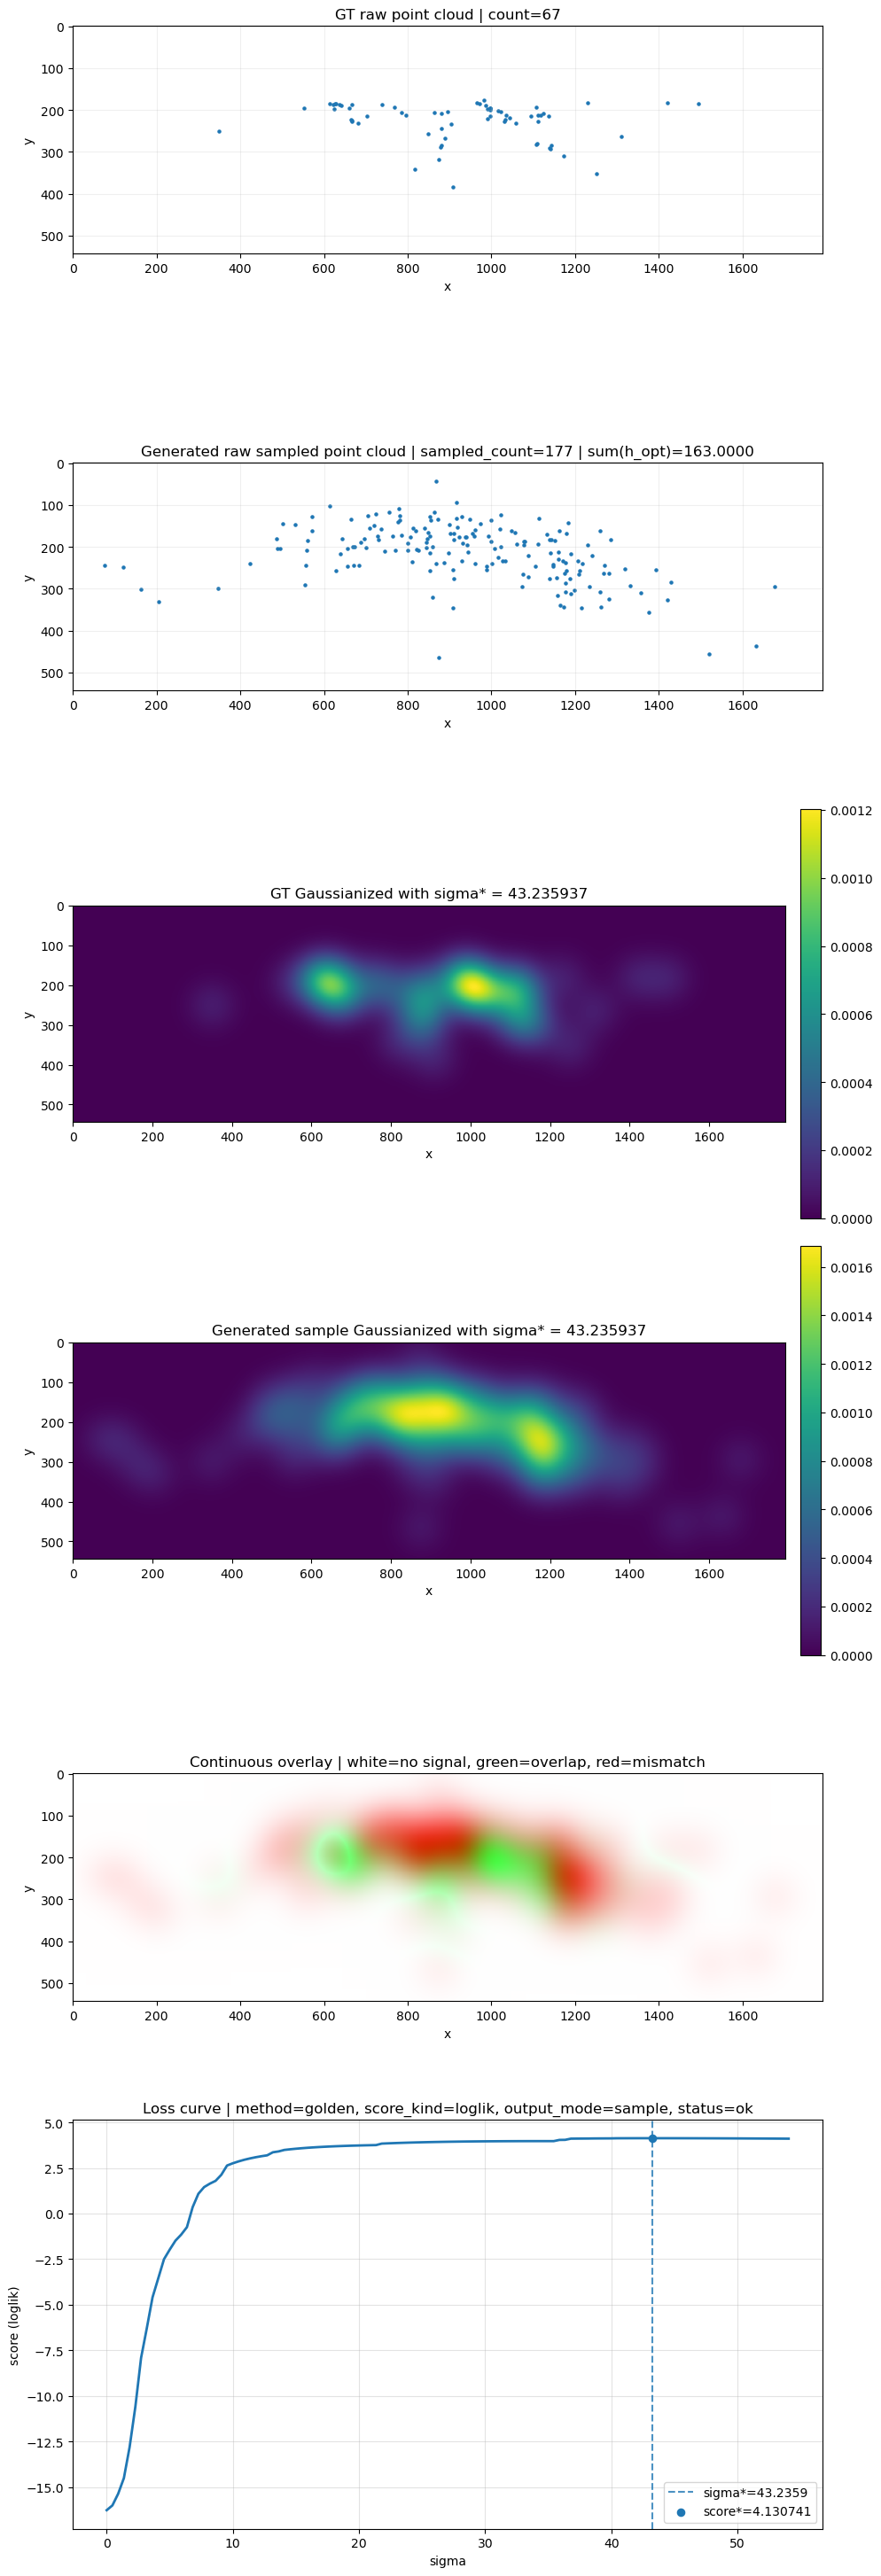

In [31]:
out = plot_gt_input_and_optimal_blur(
    grid=grid,
    gt_support=gt_support,
    method="golden",
    score_kind="loglik",
    output_mode="sample",
    run_kwargs=dict(
        sigma_min=0.0,
        sigma_max=120.0,
        max_iter=30,
        tol_sigma=0.5,
    ),
    rng_seed=0,
)

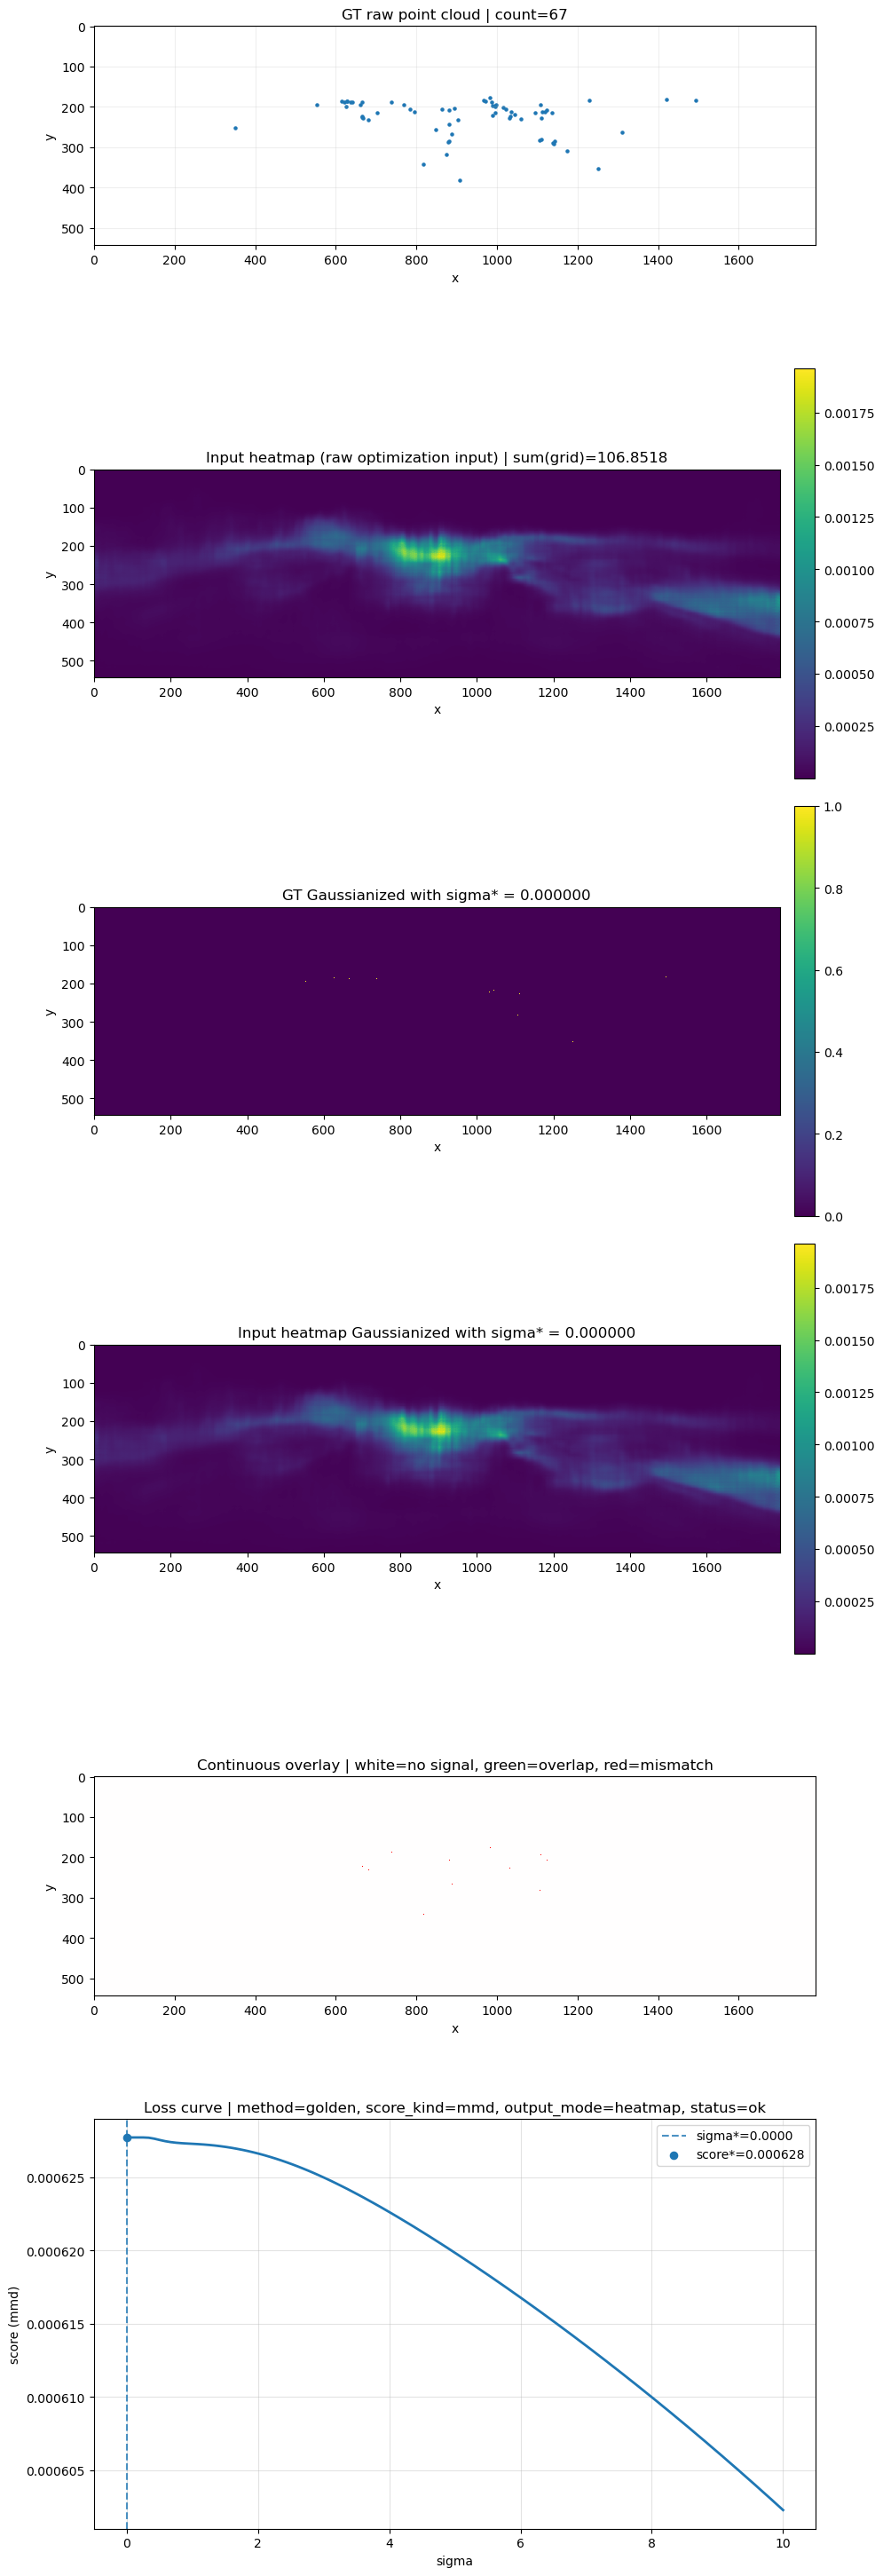

In [35]:
out = plot_gt_input_and_optimal_blur(
    grid=pred_lambda,
    gt_support=gt_support,
    method="golden",
    score_kind="mmd",
    output_mode="heatmap",
    run_kwargs=dict(
        sigma_min=0.0,
        sigma_max=120.0,
        max_iter=30,
        tol_sigma=0.5,
    ),
)

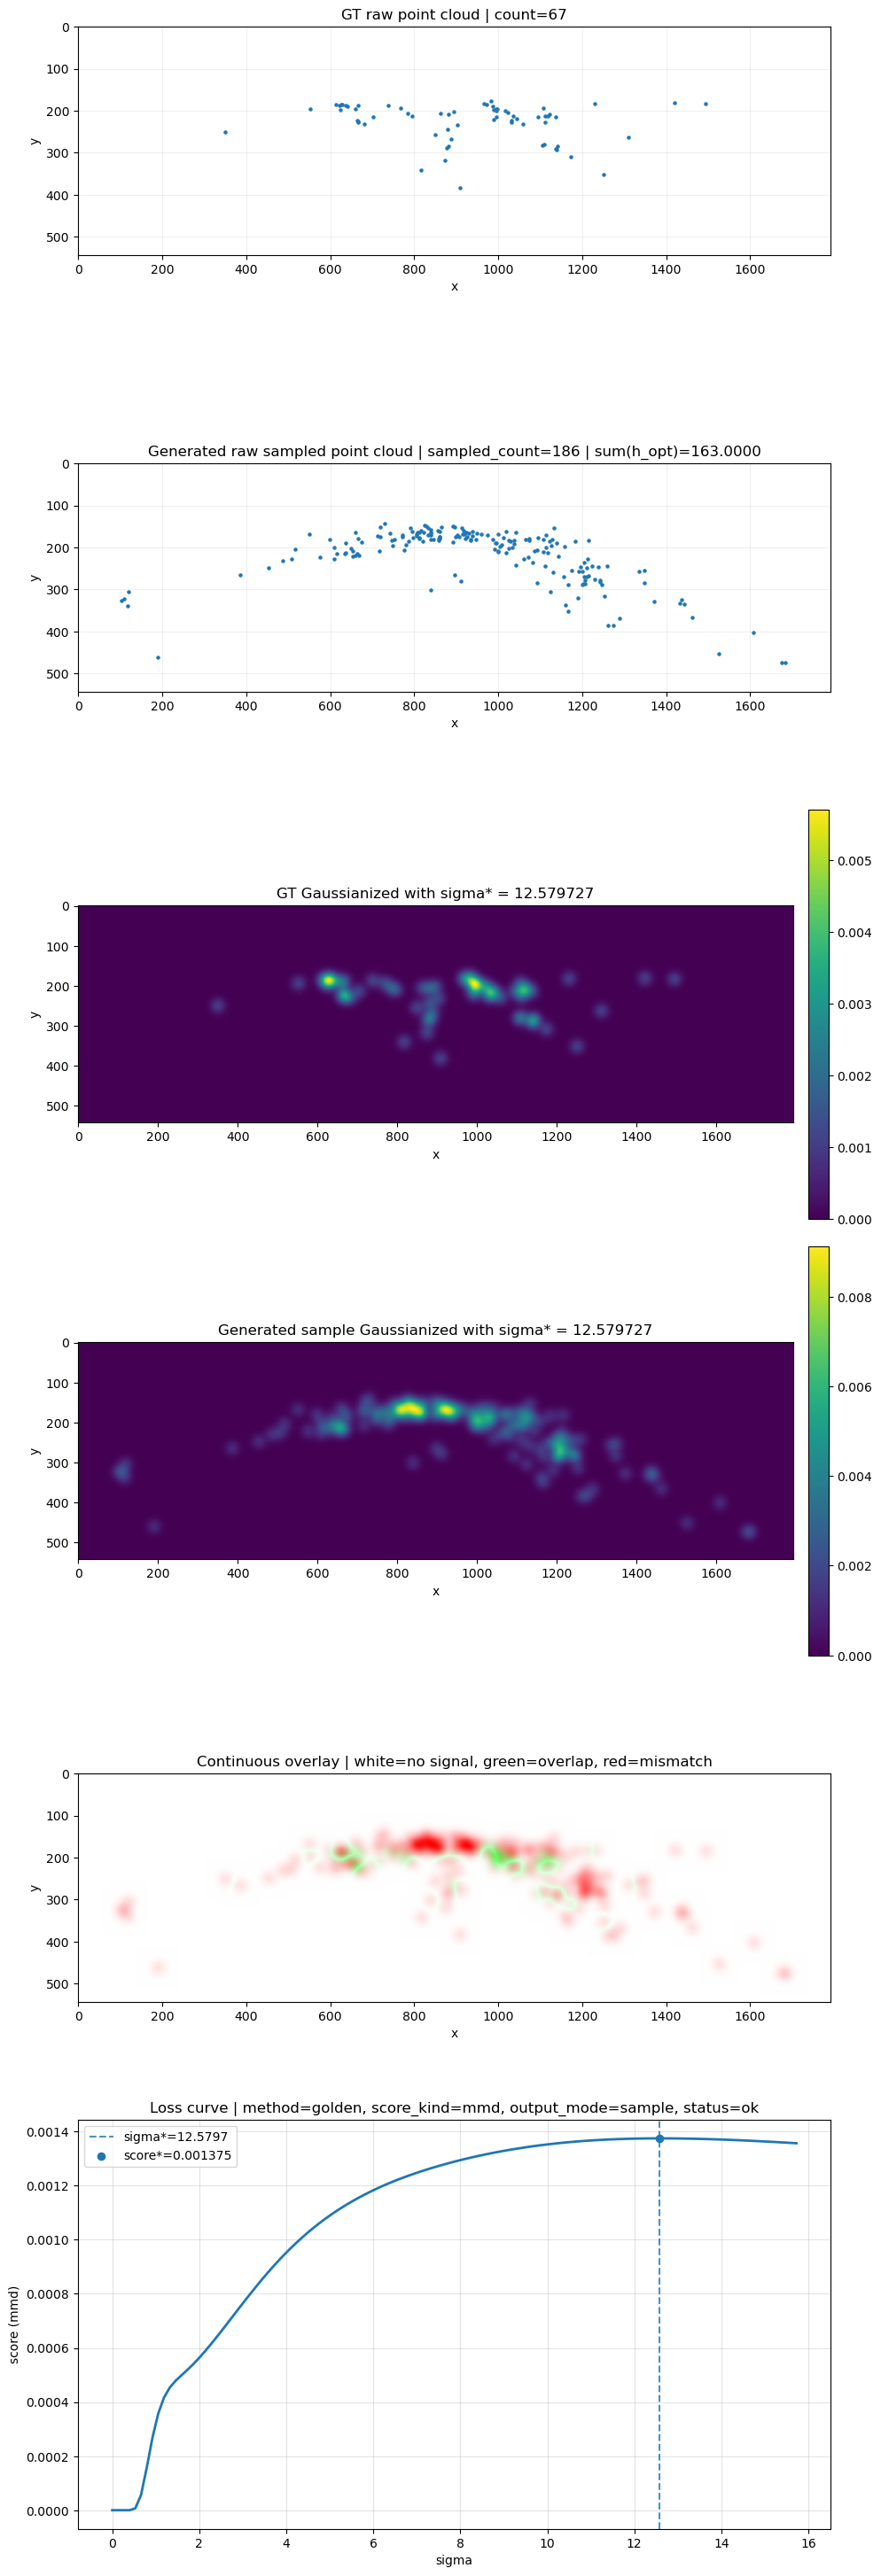

In [34]:
out = plot_gt_input_and_optimal_blur(
    grid=grid,
    gt_support=gt_support,
    method="golden",
    score_kind="mmd",
    output_mode="sample",
    run_kwargs=dict(
        sigma_min=0.0,
        sigma_max=120.0,
        max_iter=30,
        tol_sigma=0.5,
    ),
    rng_seed=0,
)

In [19]:
import math
import time
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# settings
# ------------------------------------------------------------
TRUNCATE_VALUES = [2.0, 2.5, 3.0, 3.5, 4.0, 5.0, 6.0]
TRUNCATE_REF = 6.0

SIGMA_MIN = 0.0
SIGMA_MAX = 120.0
MAX_ITER = 30
TOL_SIGMA = 0.5
EPS_H = EPS_LOG

INPUT_TYPES = ["heatmap", "sampled_pointcloud"]


# ------------------------------------------------------------
# local helpers: golden + loglik + custom truncate
# ------------------------------------------------------------
def gaussianize_grid_trunc(grid, sigma, truncate):
    x = prepare_grid(grid)
    mass = x.sum()

    if mass <= 0:
        return np.zeros_like(x, dtype=np.float64)

    if float(sigma) == 0.0:
        return x.copy()

    y = gaussian_filter(
        x / mass,
        sigma=float(sigma),
        mode="constant",
        cval=0.0,
        truncate=float(truncate),
    )
    s = y.sum()
    if s > 0:
        y *= mass / s
    return y


def eval_sigma_trunc(grid, gt_support, sigma, truncate):
    if float(sigma) == 0.0:
        h = prepare_grid(grid)
    else:
        h = gaussianize_grid_trunc(grid, sigma, truncate=truncate)

    return ppp_loglik_score(
        h,
        gt_support,
        eps=EPS_H,
        normalize_by_gt=True,
    )


def optimize_sigma_golden_trunc(
    grid,
    gt_support,
    truncate,
    sigma_min=0.0,
    sigma_max=120.0,
    max_iter=30,
    tol_sigma=0.5,
    check_zero=True,
):
    x = prepare_grid(grid)
    if x.sum() <= 0:
        return {"best_sigma": sigma_min, "best_score": -np.inf}

    cache = {}

    def f(s):
        s = float(max(0.0, s))
        key = round(s, 12)
        if key not in cache:
            cache[key] = float(eval_sigma_trunc(x, gt_support, s, truncate))
        return cache[key]

    best_sigma = None
    best_score = -np.inf

    if check_zero and sigma_min == 0.0:
        s0 = f(0.0)
        best_sigma = 0.0
        best_score = s0

    left = max(sigma_min, np.finfo(np.float64).eps)
    right = sigma_max

    phi = (1.0 + math.sqrt(5.0)) / 2.0
    inv_phi = 1.0 / phi

    c = right - (right - left) * inv_phi
    d = left + (right - left) * inv_phi

    sc = f(c)
    sd = f(d)

    if sc > best_score:
        best_score = sc
        best_sigma = c
    if sd > best_score:
        best_score = sd
        best_sigma = d

    for _ in range(max_iter):
        if (right - left) < tol_sigma:
            break

        if sc < sd:
            left = c
            c = d
            sc = sd
            d = left + (right - left) * inv_phi
            sd = f(d)
            if sd > best_score:
                best_score = sd
                best_sigma = d
        else:
            right = d
            d = c
            sd = sc
            c = right - (right - left) * inv_phi
            sc = f(c)
            if sc > best_score:
                best_score = sc
                best_sigma = c

    mid = 0.5 * (left + right)
    smid = f(mid)
    if smid > best_score:
        best_score = smid
        best_sigma = mid

    return {
        "best_sigma": float(best_sigma),
        "best_score": float(best_score),
    }


# ------------------------------------------------------------
# run on all selected samples
# ------------------------------------------------------------
rows = []

for sample_idx, (h5_path, sample_key) in enumerate(selected_samples):
    print(f"[{sample_idx+1}/{len(selected_samples)}] {os.path.basename(h5_path)} / {sample_key}")

    sample = load_h5_sample(h5_path, sample_key)
    pred_lambda = sample["pred_lambda"]
    gt_support = sample["gt_support"]
    ppp = sample["ppp"]
    meta = sample["meta"]

    sampled_pc_grid, sampled_pc_meta = sample_point_cloud_from_lambda(
        pred_lambda,
        rng=np.random.default_rng(sample_idx),
        mode=POINT_SAMPLING_MODE,
        gt_count=ppp["gt_count"],
    )

    inputs_to_test = {
        "heatmap": pred_lambda,
        "sampled_pointcloud": sampled_pc_grid,
    }

    for input_type in INPUT_TYPES:
        grid = inputs_to_test[input_type]

        for trunc in TRUNCATE_VALUES:
            t0 = time.perf_counter()
            out = optimize_sigma_golden_trunc(
                grid=grid,
                gt_support=gt_support,
                truncate=trunc,
                sigma_min=SIGMA_MIN,
                sigma_max=SIGMA_MAX,
                max_iter=MAX_ITER,
                tol_sigma=TOL_SIGMA,
                check_zero=True,
            )
            elapsed = time.perf_counter() - t0

            rows.append({
                "h5_file": meta["h5_file"],
                "sample_key": meta["sample_key"],
                "input_type": input_type,
                "truncate": float(trunc),
                "best_sigma": float(out["best_sigma"]),
                "best_score": float(out["best_score"]),
                "runtime_s": float(elapsed),
            })

df_trunc = pd.DataFrame(rows)
print("Rows in df_trunc:", len(df_trunc))


# ------------------------------------------------------------
# compare to high-truncate reference
# ------------------------------------------------------------
df_ref = (
    df_trunc[df_trunc["truncate"] == TRUNCATE_REF]
    .rename(columns={
        "best_sigma": "best_sigma_ref",
        "best_score": "best_score_ref",
    })[
        ["h5_file", "sample_key", "input_type", "best_sigma_ref", "best_score_ref"]
    ]
)

df_cmp = df_trunc.merge(
    df_ref,
    on=["h5_file", "sample_key", "input_type"],
    how="left",
)

df_cmp["abs_score_diff"] = np.abs(df_cmp["best_score"] - df_cmp["best_score_ref"])
df_cmp["abs_sigma_diff"] = np.abs(df_cmp["best_sigma"] - df_cmp["best_sigma_ref"])

summary = (
    df_cmp.groupby(["input_type", "truncate"], as_index=False)
    .agg(
        mean_runtime_s=("runtime_s", "mean"),
        std_runtime_s=("runtime_s", "std"),
        mean_abs_score_diff=("abs_score_diff", "mean"),
        std_abs_score_diff=("abs_score_diff", "std"),
        mean_abs_sigma_diff=("abs_sigma_diff", "mean"),
        std_abs_sigma_diff=("abs_sigma_diff", "std"),
    )
    .sort_values(["input_type", "truncate"])
)

summary

[1/1] rank00.h5 / sample_000000
Rows in df_trunc: 14


,input_type,truncate,mean_runtime_s,std_runtime_s,mean_abs_score_diff,std_abs_score_diff,mean_abs_sigma_diff,std_abs_sigma_diff
0,heatmap,2.0,0.670286,NaN,0.000000e+00,NaN,0.000000,NaN
1,heatmap,2.5,0.786741,NaN,0.000000e+00,NaN,0.000000,NaN
2,heatmap,3.0,0.885171,NaN,0.000000e+00,NaN,0.000000,NaN
3,heatmap,3.5,1.018151,NaN,0.000000e+00,NaN,0.000000,NaN
4,heatmap,4.0,1.142233,NaN,0.000000e+00,NaN,0.000000,NaN
5,heatmap,5.0,1.425023,NaN,0.000000e+00,NaN,0.000000,NaN
6,heatmap,6.0,1.715156,NaN,0.000000e+00,NaN,0.000000,NaN
7,sampled_pointcloud,2.0,1.833635,NaN,2.362391e-02,NaN,3.814721,NaN
8,sampled_pointcloud,2.5,2.376936,NaN,5.260352e-03,NaN,4.878371,NaN
9,sampled_pointcloud,3.0,2.667336,NaN,3.856690e-04,NaN,0.230325,NaN


In [29]:
import math
import time
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# settings
# ------------------------------------------------------------
TRUNCATE_VALUES = [2.0, 2.5, 3.0, 3.5, 4.0, 5.0, 6.0]
TRUNCATE_REF = 6.0

SIGMA_MIN = 0.0
SIGMA_MAX = 120.0
MAX_ITER = 30
TOL_SIGMA = 0.5
EPS_H = EPS_LOG

INPUT_TYPES = ["heatmap", "sampled_pointcloud"]


# ------------------------------------------------------------
# local helpers: golden (log-scale) + loglik + custom truncate
# ------------------------------------------------------------
def gaussianize_grid_trunc(grid, sigma, truncate):
    x = prepare_grid(grid)
    mass = x.sum()

    if mass <= 0:
        return np.zeros_like(x, dtype=np.float64)

    if float(sigma) == 0.0:
        return x.copy()

    y = gaussian_filter(
        x / mass,
        sigma=float(sigma),
        mode="constant",
        cval=0.0,
        truncate=float(truncate),
    )
    s = y.sum()
    if s > 0:
        y *= mass / s
    return y


def eval_sigma_trunc(grid, gt_support, sigma, truncate):
    if float(sigma) == 0.0:
        h = prepare_grid(grid)
    else:
        h = gaussianize_grid_trunc(grid, sigma, truncate=truncate)

    return ppp_loglik_score(
        h,
        gt_support,
        eps=EPS_H,
        normalize_by_gt=True,
    )


def optimize_sigma_golden_trunc_logscale(
    grid,
    gt_support,
    truncate,
    sigma_min=0.0,
    sigma_max=120.0,
    max_iter=30,
    tol_sigma=0.5,
    check_zero=True,
):
    x = prepare_grid(grid)
    if x.sum() <= 0:
        return {"best_sigma": sigma_min, "best_score": -np.inf}

    cache = {}

    def f(s):
        s = float(max(0.0, s))
        key = round(s, 12)
        if key not in cache:
            cache[key] = float(eval_sigma_trunc(x, gt_support, s, truncate))
        return cache[key]

    best_sigma = None
    best_score = -np.inf

    if check_zero and sigma_min == 0.0:
        s0 = f(0.0)
        best_sigma = 0.0
        best_score = s0

    log_left = math.log(max(sigma_min, 0.1))
    log_right = math.log(max(sigma_max, 0.1))

    phi = (1.0 + math.sqrt(5.0)) / 2.0
    inv_phi = 1.0 / phi

    c = log_right - (log_right - log_left) * inv_phi
    d = log_left + (log_right - log_left) * inv_phi

    c_sigma = math.exp(c)
    d_sigma = math.exp(d)

    sc = f(c_sigma)
    sd = f(d_sigma)

    if sc > best_score:
        best_score = sc
        best_sigma = c_sigma
    if sd > best_score:
        best_score = sd
        best_sigma = d_sigma

    for _ in range(max_iter):
        if (math.exp(log_right) - math.exp(log_left)) < tol_sigma:
            break

        if sc < sd:
            log_left = c
            c = d
            sc = sd
            d = log_left + (log_right - log_left) * inv_phi
            d_sigma = math.exp(d)
            sd = f(d_sigma)
            if sd > best_score:
                best_score = sd
                best_sigma = d_sigma
        else:
            log_right = d
            d = c
            sd = sc
            c = log_right - (log_right - log_left) * inv_phi
            c_sigma = math.exp(c)
            sc = f(c_sigma)
            if sc > best_score:
                best_score = sc
                best_sigma = c_sigma

    mid_sigma = math.exp(0.5 * (log_left + log_right))
    smid = f(mid_sigma)
    if smid > best_score:
        best_score = smid
        best_sigma = mid_sigma

    return {
        "best_sigma": float(best_sigma),
        "best_score": float(best_score),
    }


# ------------------------------------------------------------
# run on all selected samples
# ------------------------------------------------------------
rows = []

for sample_idx, (h5_path, sample_key) in enumerate(selected_samples):
    print(f"[{sample_idx+1}/{len(selected_samples)}] {os.path.basename(h5_path)} / {sample_key}")

    sample = load_h5_sample(h5_path, sample_key)
    pred_lambda = sample["pred_lambda"]
    gt_support = sample["gt_support"]
    ppp = sample["ppp"]
    meta = sample["meta"]

    sampled_pc_grid, sampled_pc_meta = sample_point_cloud_from_lambda(
        pred_lambda,
        rng=np.random.default_rng(sample_idx),
        mode=POINT_SAMPLING_MODE,
        gt_count=ppp["gt_count"],
    )

    inputs_to_test = {
        "heatmap": pred_lambda,
        "sampled_pointcloud": sampled_pc_grid,
    }

    for input_type in INPUT_TYPES:
        grid = inputs_to_test[input_type]

        for trunc in TRUNCATE_VALUES:
            t0 = time.perf_counter()
            out = optimize_sigma_golden_trunc_logscale(
                grid=grid,
                gt_support=gt_support,
                truncate=trunc,
                sigma_min=SIGMA_MIN,
                sigma_max=SIGMA_MAX,
                max_iter=MAX_ITER,
                tol_sigma=TOL_SIGMA,
                check_zero=True,
            )
            elapsed = time.perf_counter() - t0

            rows.append({
                "h5_file": meta["h5_file"],
                "sample_key": meta["sample_key"],
                "input_type": input_type,
                "truncate": float(trunc),
                "best_sigma": float(out["best_sigma"]),
                "best_score": float(out["best_score"]),
                "runtime_s": float(elapsed),
            })

df_trunc = pd.DataFrame(rows)
print("Rows in df_trunc:", len(df_trunc))


# ------------------------------------------------------------
# compare to high-truncate reference
# ------------------------------------------------------------
df_ref = (
    df_trunc[df_trunc["truncate"] == TRUNCATE_REF]
    .rename(columns={
        "best_sigma": "best_sigma_ref",
        "best_score": "best_score_ref",
    })[
        ["h5_file", "sample_key", "input_type", "best_sigma_ref", "best_score_ref"]
    ]
)

df_cmp = df_trunc.merge(
    df_ref,
    on=["h5_file", "sample_key", "input_type"],
    how="left",
)

df_cmp["abs_score_diff"] = np.abs(df_cmp["best_score"] - df_cmp["best_score_ref"])
df_cmp["abs_sigma_diff"] = np.abs(df_cmp["best_sigma"] - df_cmp["best_sigma_ref"])

summary = (
    df_cmp.groupby(["input_type", "truncate"], as_index=False)
    .agg(
        mean_runtime_s=("runtime_s", "mean"),
        std_runtime_s=("runtime_s", "std"),
        mean_abs_score_diff=("abs_score_diff", "mean"),
        std_abs_score_diff=("abs_score_diff", "std"),
        mean_abs_sigma_diff=("abs_sigma_diff", "mean"),
        std_abs_sigma_diff=("abs_sigma_diff", "std"),
    )
    .sort_values(["input_type", "truncate"])
)

summary

[1/12] rank00.h5 / sample_000000
[2/12] rank01.h5 / sample_000006
[3/12] rank01.h5 / sample_000086
[4/12] rank01.h5 / sample_000019
[5/12] rank03.h5 / sample_000031
[6/12] rank01.h5 / sample_000101
[7/12] rank02.h5 / sample_000031
[8/12] rank03.h5 / sample_000036
[9/12] rank01.h5 / sample_000056
[10/12] rank00.h5 / sample_000098
[11/12] rank00.h5 / sample_000068
[12/12] rank00.h5 / sample_000032
Rows in df_trunc: 168


,input_type,truncate,mean_runtime_s,std_runtime_s,mean_abs_score_diff,std_abs_score_diff,mean_abs_sigma_diff,std_abs_sigma_diff
0,heatmap,2.0,0.186828,0.137045,3.351948e-04,5.556697e-04,0.435601,0.564097
1,heatmap,2.5,0.213821,0.153645,1.535827e-04,2.587972e-04,0.128452,0.175366
2,heatmap,3.0,0.229726,0.176644,5.471566e-05,8.924110e-05,0.035147,0.072726
3,heatmap,3.5,0.257219,0.221632,1.346848e-05,2.297661e-05,0.000000,0.000000
4,heatmap,4.0,0.279776,0.247447,2.390701e-06,3.495824e-06,0.018491,0.038282
5,heatmap,5.0,0.335456,0.301171,1.974935e-08,3.427550e-08,0.000000,0.000000
6,heatmap,6.0,0.385820,0.362347,0.000000e+00,0.000000e+00,0.000000,0.000000
7,sampled_pointcloud,2.0,2.197221,1.315840,1.362587e-01,9.298765e-02,12.516677,10.386743
8,sampled_pointcloud,2.5,2.266246,1.581432,8.382704e-02,7.351665e-02,4.809184,5.720874
9,sampled_pointcloud,3.0,2.802034,1.855373,4.967406e-02,5.081039e-02,4.930706,5.643840


In [27]:
# import matplotlib.pyplot as plt

# for input_type in INPUT_TYPES:
#     sub = summary[summary["input_type"] == input_type].sort_values("truncate")

#     plt.figure(figsize=(6, 4))
#     plt.plot(sub["truncate"], sub["mean_abs_score_diff"], marker="o")
#     plt.xlabel("truncate")
#     plt.ylabel("mean abs score deviation")
#     plt.title(f"Score deviation vs truncate ({input_type})")
#     plt.grid(True, alpha=0.3)
#     plt.show()

#     plt.figure(figsize=(6, 4))
#     plt.plot(sub["truncate"], sub["mean_abs_sigma_diff"], marker="o")
#     plt.xlabel("truncate")
#     plt.ylabel("mean abs sigma deviation")
#     plt.title(f"Sigma deviation vs truncate ({input_type})")
#     plt.grid(True, alpha=0.3)
#     plt.show()

#     plt.figure(figsize=(6, 4))
#     plt.plot(sub["truncate"], sub["mean_runtime_s"], marker="o")
#     plt.xlabel("truncate")
#     plt.ylabel("mean runtime [s]")
#     plt.title(f"Runtime vs truncate ({input_type})")
#     plt.grid(True, alpha=0.3)
#     plt.show()

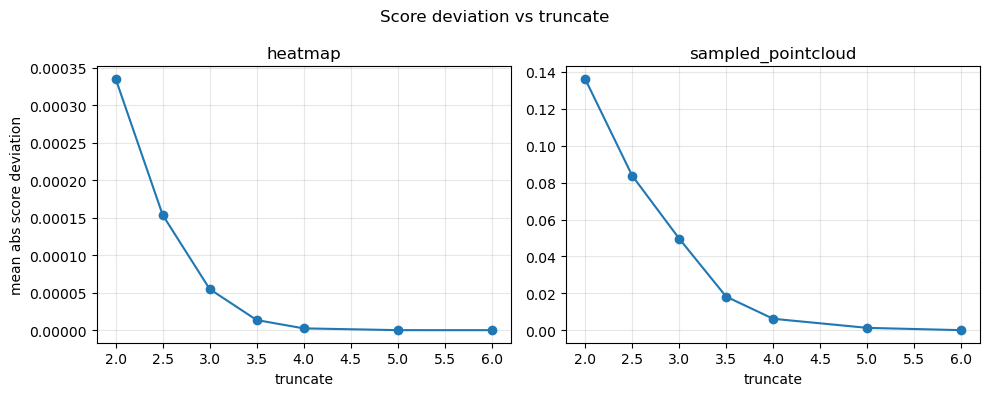

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, input_type in zip(axes, INPUT_TYPES):
    sub = summary[summary["input_type"] == input_type].sort_values("truncate")
    ax.plot(sub["truncate"], sub["mean_abs_score_diff"], marker="o")
    ax.set_xlabel("truncate")
    ax.set_title(input_type)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("mean abs score deviation")

plt.suptitle("Score deviation vs truncate")
plt.tight_layout()
plt.show()